# Reconnaître un mouvement : circle / horizontal / vertical

Données : `dataset_group3/`, 3 mouvements x 100 enregistrements. Chaque enregistrement = 75 mesures x 6 axes (acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z).


In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"   # évite un blocage torch + scikit-learn sur macOS

import glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset_group3").exists())
CLASSES = ["circle", "horizontal", "vertical"]

def normaliser(signal):
    return (signal - signal.mean(0)) / (signal.std(0) + 1e-8)

def charger(dossier):
    X, y = [], []
    for label, classe in enumerate(CLASSES):
        for f in sorted(glob.glob(str(ROOT / dossier / classe / "*.csv"))):
            X.append(normaliser(np.loadtxt(f, delimiter=",", skiprows=1)))
            y.append(label)
    return np.stack(X).astype(np.float32), np.array(y)

X, y = charger("dataset_group3")
print(X.shape)   # (300 enregistrements, 75 mesures, 6 axes)

(300, 75, 6)


In [3]:
import torch
torch.manual_seed(42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Conv1d attend (batch, canaux, temps) -> (N, 6 axes, 75 mesures)
Xtr = torch.tensor(X_train).permute(0, 2, 1)
Xte = torch.tensor(X_test).permute(0, 2, 1)
ytr = torch.tensor(y_train)
yte = torch.tensor(y_test)
print(Xtr.shape, Xte.shape)


torch.Size([240, 6, 75]) torch.Size([60, 6, 75])


In [4]:
class CNN(nn.Module):
    def __init__(self, n_axes=6, n_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_axes, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),     nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),     nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN()


In [5]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(Xtr, ytr), batch_size=32, shuffle=True
)

for epoch in range(40):
    model.train()
    total = 0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
    if (epoch + 1) % 10 == 0:
        model.eval()
        with torch.no_grad():
            acc = (model(Xte).argmax(1) == yte).float().mean().item()
        print(f"epoch {epoch+1:2d}  loss {total/len(Xtr):.3f}  acc test {acc:.2%}")


epoch 10  loss 0.054  acc test 100.00%
epoch 20  loss 0.016  acc test 100.00%
epoch 30  loss 0.008  acc test 100.00%
epoch 40  loss 0.004  acc test 100.00%


Accuracy  : 1.000
Precision : 1.000
Recall    : 1.000
F1        : 1.000

              precision    recall  f1-score   support

      circle      1.000     1.000     1.000        20
  horizontal      1.000     1.000     1.000        20
    vertical      1.000     1.000     1.000        20

    accuracy                          1.000        60
   macro avg      1.000     1.000     1.000        60
weighted avg      1.000     1.000     1.000        60



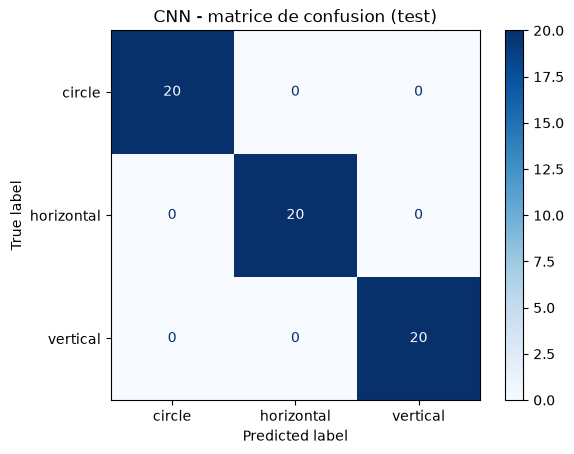

In [6]:
model.eval()
with torch.no_grad():
    y_pred = model(Xte).argmax(1).numpy()

# Métriques globales (moyenne "macro" = moyenne des 3 classes, chacune pèse pareil)
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision : {precision_score(y_test, y_pred, average='macro'):.3f}")
print(f"Recall    : {recall_score(y_test, y_pred, average='macro'):.3f}")
print(f"F1        : {f1_score(y_test, y_pred, average='macro'):.3f}")

# Détail par mouvement
# precision = parmi les prédictions "circle", combien sont vraiment des circle
# recall    = parmi les vrais circle, combien le modèle a retrouvés
print()
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

# Matrice de confusion : lignes = vrai mouvement, colonnes = mouvement prédit
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues")
plt.title("CNN - matrice de confusion (test)")
plt.show()

In [7]:
def predire(chemin_csv):
    s = normaliser(np.loadtxt(chemin_csv, delimiter=",", skiprows=1)).astype(np.float32)
    x = torch.tensor(s).T.unsqueeze(0)          # (1, 6, 75)
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0]
    return CLASSES[p.argmax().item()], dict(zip(CLASSES, p.numpy().round(3)))

predire(ROOT / "dataset_group3/circle/3_Circle_1.csv")
# -> ('circle', {'circle': 0.997, 'horizontal': 0.002, 'vertical': 0.001})


('circle',
 {'circle': np.float32(0.997),
  'horizontal': np.float32(0.002),
  'vertical': np.float32(0.001)})

## Taille / quantization -> it/s

On compare 3 versions du même modèle :
- **float32** : le modèle d'origine (chaque poids = 4 octets)
- **float16** : poids en demi-précision (2 octets)
- **int8** : poids et calculs en entiers 8 bits (1 octet), quantization statique PyTorch

Pour chacune : taille du fichier, vitesse (it/s = nombre de prédictions d'un enregistrement par seconde) et accuracy, pour vérifier que la compression ne dégrade pas le modèle.

Attention : la vitesse dépend de la machine. Sur un Mac, int8 peut être plus lent que float32, car le modèle est minuscule et les conversions coûtent plus cher que le calcul. Le gain de vitesse de l'int8 se voit surtout sur un microcontrôleur ou un téléphone.

In [8]:
import io, time, copy, warnings
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx

def taille_ko(m):
    buf = io.BytesIO()
    torch.save(m.state_dict(), buf)
    return buf.tell() / 1024

def vitesse(m, n=2000):
    x = Xte[:1]                       # un seul enregistrement, comme en temps réel
    with torch.no_grad():
        for _ in range(50):           # échauffement
            m(x)
        t = time.perf_counter()
        for _ in range(n):
            m(x)
    return n / (time.perf_counter() - t)

# float16
class EnFloat16(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.m = copy.deepcopy(m).half()
    def forward(self, x):
        return self.m(x.half()).float()

model_fp16 = EnFloat16(model).eval()

# int8 : on calibre sur les données d'entraînement pour fixer les échelles
torch.backends.quantized.engine = "qnnpack"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    prep = prepare_fx(copy.deepcopy(model).eval(), get_default_qconfig_mapping("qnnpack"), example_inputs=(Xte[:1],))
    with torch.no_grad():
        prep(Xtr)
    model_int8 = convert_fx(prep)

print(f"{'version':8s} {'taille':>9s} {'vitesse':>11s} {'accuracy':>9s}")
for nom, m in [("float32", model), ("float16", model_fp16), ("int8", model_int8)]:
    with torch.no_grad():
        acc = accuracy_score(y_test, m(Xte).argmax(1).numpy())
    print(f"{nom:8s} {taille_ko(m):6.1f} Ko {vitesse(m):7.0f} it/s {acc:9.3f}")

version     taille     vitesse  accuracy
float32   102.9 Ko    6596 it/s     1.000
float16    55.2 Ko    2469 it/s     1.000
int8       30.6 Ko    1703 it/s     1.000


## 2 axes / 4 axes / 6 axes

Pour savoir quels capteurs sont vraiment utiles, on ré-entraîne le CNN avec seulement une partie des axes. On essaie **toutes** les combinaisons de 2 axes (15), de 4 axes (15) et les 6 axes (1), soit 31 entraînements (environ 3 minutes).

Chaque modèle est évalué sur :
- le **test de group3** (même groupe que l'entraînement)
- **dataset_group2** (un autre groupe, jamais vu) : c'est la mesure la plus honnête, car sur group3 presque tout fait 100 %.

In [9]:
from itertools import combinations

AXES = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]
X2, y2 = charger("dataset_group2")   # autre groupe, jamais vu à l'entraînement

def entrainer(X_np, y_np, epochs=40):
    torch.manual_seed(42)
    Xt = torch.tensor(X_np).permute(0, 2, 1)
    m = CNN(n_axes=Xt.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xt, torch.tensor(y_np)), batch_size=32, shuffle=True
    )
    for _ in range(epochs):
        m.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(m(xb), yb).backward()
            opt.step()
    return m.eval()

def predire_lot(m, X_np):
    with torch.no_grad():
        return m(torch.tensor(X_np).permute(0, 2, 1)).argmax(1).numpy()

resultats = []
for k in (2, 4, 6):
    for combo in combinations(range(6), k):
        idx = list(combo)
        m = entrainer(X_train[:, :, idx], y_train)
        p_test = predire_lot(m, X_test[:, :, idx])
        p_g2 = predire_lot(m, X2[:, :, idx])
        resultats.append({
            "n_axes": k,
            "axes": " + ".join(AXES[i] for i in idx),
            "acc_test": accuracy_score(y_test, p_test),
            "acc_group2": accuracy_score(y2, p_g2),
            # zero_division=0 : si une classe n'est jamais prédite, sa precision vaut 0
            "precision_group2": precision_score(y2, p_g2, average="macro", zero_division=0),
            "recall_group2": recall_score(y2, p_g2, average="macro", zero_division=0),
            "idx": idx,
        })
    print(f"{k} axes : fait")

# Meilleure combinaison pour 2, 4 et 6 axes (classée sur group2)
print()
print(f"{'n':>2s}  {'axes':52s} {'acc test':>8s} {'acc g2':>7s} {'prec g2':>8s} {'rec g2':>7s}")
for k in (2, 4, 6):
    r = max((r for r in resultats if r["n_axes"] == k), key=lambda r: r["acc_group2"])
    print(f"{k:2d}  {r['axes']:52s} {r['acc_test']:8.3f} {r['acc_group2']:7.3f} "
          f"{r['precision_group2']:8.3f} {r['recall_group2']:7.3f}")

2 axes : fait
4 axes : fait
6 axes : fait

 n  axes                                                 acc test  acc g2  prec g2  rec g2
 2  acc_x + acc_y                                           1.000   0.992    0.992   0.992
 4  acc_x + acc_y + acc_z + gyro_y                          1.000   0.992    0.992   0.992
 6  acc_x + acc_y + acc_z + gyro_x + gyro_y + gyro_z        1.000   0.860    0.862   0.860


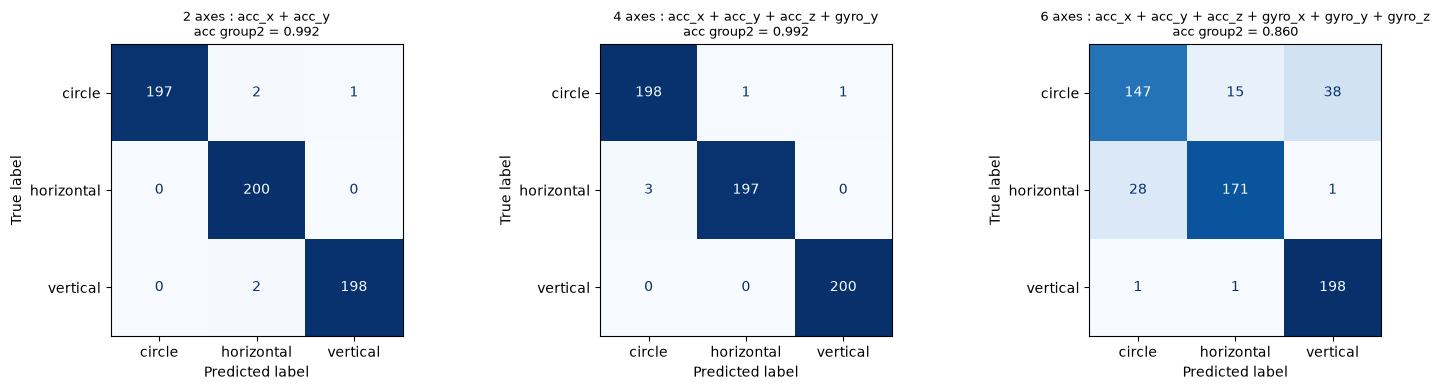

In [10]:
# Matrice de confusion sur group2 pour la meilleure combinaison de 2, 4 et 6 axes
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axs, (2, 4, 6)):
    r = max((r for r in resultats if r["n_axes"] == k), key=lambda r: r["acc_group2"])
    m = entrainer(X_train[:, :, r["idx"]], y_train)
    p = predire_lot(m, X2[:, :, r["idx"]])
    ConfusionMatrixDisplay(confusion_matrix(y2, p), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{k} axes : {r['axes']}\nacc group2 = {r['acc_group2']:.3f}", fontsize=9)
plt.tight_layout()
plt.show()

## Comparaison : modèle group3 vs modèle group2

On entraîne le même CNN (6 axes) sur `dataset_group2` (600 enregistrements), avec le même découpage 80 % / 20 %.

Chaque modèle est testé :
- sur le **test de son propre groupe** (données jamais vues, mais même personne / même façon de faire le geste)
- sur **tout l'autre groupe** (jamais vu du tout) : c'est ce qui montre si le modèle généralise à d'autres personnes.

group2 : (600, 75, 6) -> train 480 / test 120

modèle         testé sur        n  accuracy  precision  recall     f1
Modèle group3  test group3     60     1.000      1.000   1.000  1.000
Modèle group3  tout group2    600     0.860      0.862   0.860  0.857
Modèle group2  test group2    120     0.992      0.992   0.992  0.992
Modèle group2  tout group3    300     0.690      0.795   0.690  0.587


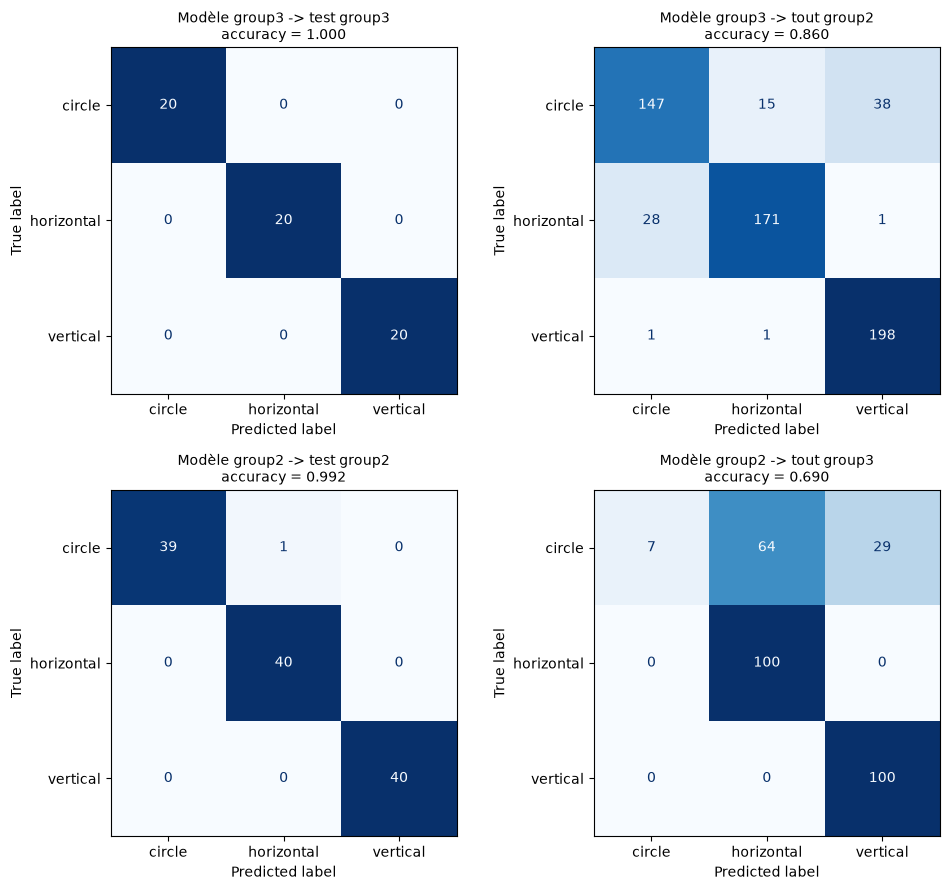

In [11]:
def entrainer_cnn(X_np, y_np, epochs=40):
    torch.manual_seed(42)
    Xt = torch.tensor(X_np).permute(0, 2, 1)
    m = CNN(n_axes=Xt.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xt, torch.tensor(y_np)), batch_size=32, shuffle=True
    )
    for _ in range(epochs):
        m.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(m(xb), yb).backward()
            opt.step()
    return m.eval()

def predire_lot(m, X_np):
    with torch.no_grad():
        return m(torch.tensor(X_np).permute(0, 2, 1)).argmax(1).numpy()

# group2 : 600 enregistrements, même découpage 80 % entraînement / 20 % test
X_g2, y_g2 = charger("dataset_group2")
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_g2, y_g2, test_size=0.2, stratify=y_g2, random_state=42
)
print("group2 :", X_g2.shape, "-> train", X2_train.shape[0], "/ test", X2_test.shape[0])

model_g3 = model                               # entraîné plus haut sur group3
model_g2 = entrainer_cnn(X2_train, y2_train)   # nouveau, entraîné sur group2

# Chaque modèle est testé sur le test de son groupe ET sur tout l'autre groupe
evaluations = {
    ("Modèle group3", "test group3"): (model_g3, X_test,  y_test),
    ("Modèle group3", "tout group2"): (model_g3, X_g2,    y_g2),
    ("Modèle group2", "test group2"): (model_g2, X2_test, y2_test),
    ("Modèle group2", "tout group3"): (model_g2, X,       y),
}

print()
print(f"{'modèle':14s} {'testé sur':13s} {'n':>4s} {'accuracy':>9s} {'precision':>10s} {'recall':>7s} {'f1':>6s}")
preds = {}
for (nom, jeu), (m, Xe, ye) in evaluations.items():
    p = predire_lot(m, Xe)
    preds[(nom, jeu)] = (ye, p)
    print(f"{nom:14s} {jeu:13s} {len(ye):4d} {accuracy_score(ye, p):9.3f} "
          f"{precision_score(ye, p, average='macro', zero_division=0):10.3f} "
          f"{recall_score(ye, p, average='macro', zero_division=0):7.3f} "
          f"{f1_score(ye, p, average='macro', zero_division=0):6.3f}")

fig, axs = plt.subplots(2, 2, figsize=(10, 9))
for ax, ((nom, jeu), (ye, p)) in zip(axs.ravel(), preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(ye, p), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nom} -> {jeu}\naccuracy = {accuracy_score(ye, p):.3f}", fontsize=10)
plt.tight_layout()
plt.show()

### Résultat

| modèle | testé sur | accuracy | precision | recall |
|---|---|---|---|---|
| group3 | test group3 (60) | 1.000 | 1.000 | 1.000 |
| group3 | tout group2 (600) | 0.860 | 0.862 | 0.860 |
| group2 | test group2 (120) | 0.992 | 0.992 | 0.992 |
| group2 | tout group3 (300) | 0.690 | 0.795 | 0.690 |

- Sur leur propre groupe, les deux modèles sont presque parfaits.
- Sur l'autre groupe, ils baissent : le modèle a appris la façon de faire le geste d'un groupe, pas seulement le geste.
- Le problème vient surtout de **circle** : le modèle group2 ne reconnaît que 7 circle sur 100 de group3 (il les prend pour horizontal ou vertical). Les deux groupes ne font donc pas le cercle de la même façon : voir les graphiques ci-dessous (vitesse et orientation du capteur).
- Pour un modèle qui marche pour tout le monde : entraîner sur les deux groupes ensemble.

## Pourquoi les "circle" des deux groupes sont différents

On compare uniquement les enregistrements **circle** de group2 et group3 sur 4 critères :

- **Vitesse** : combien de tours sont faits en 1,5 s
- **Sens** : horaire ou anti-horaire
- **Orientation du capteur** : quels axes bougent ensemble
- **Taille** : **impossible à mesurer ici**. Les CSV de group3 sont déjà normalisés (moyenne 0, écart-type 1 sur chaque axe), donc l'amplitude du geste a été effacée avant qu'on reçoive les fichiers. Pour la même raison, la gravité (moyenne) a été retirée dans les deux groupes, donc on ne peut pas voir directement comment le capteur était posé. On l'observe indirectement avec les corrélations entre axes.

In [ ]:
# --- Préparation : les "circle" des deux groupes ---
AXES = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]
COULEURS = {"group2": "#2a78d6", "group3": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.axisbelow": True})

def circles(dossier):
    Xg, yg = charger(dossier)                      # déjà normalisés par axe
    return Xg[yg == CLASSES.index("circle")]

C = {"group2": circles("dataset_group2"), "group3": circles("dataset_group3")}
for g, A in C.items():
    print(g, ":", len(A), "circles")

# 1) VITESSE : combien de tours dans les 1,5 s ?
#    On cherche la fréquence la plus forte de acc_x + acc_y (FFT).
#    1 tour en 1,5 s = 0,67 Hz ; 2 tours = 1,33 Hz ; 3 tours = 2 Hz
def nb_tours(A):
    puissance = (np.abs(np.fft.rfft(A[:, :, :2], axis=1)) ** 2).sum(2)
    return puissance[:, 1:8].argmax(1) + 1

fig, ax = plt.subplots(figsize=(7, 4))
largeur = 0.38
for i, (g, A) in enumerate(C.items()):
    n = nb_tours(A)
    pct = [np.mean(n == k) * 100 for k in (1, 2, 3)]
    pos = np.arange(3) + (i - 0.5) * largeur
    barres = ax.bar(pos, pct, largeur - 0.02, color=COULEURS[g], label=g)
    ax.bar_label(barres, fmt="%.0f %%", fontsize=9, color="#3d3d3a")
ax.set_xticks(range(3), ["1 tour\n(lent)", "2 tours", "3 tours\n(rapide)"])
ax.set_ylabel("% des enregistrements circle")
ax.set_title("Vitesse : nombre de cercles faits en 1,5 s")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# 2) SENS : trajectoire acc_x / acc_y (le "dessin" du cercle vu par le capteur)
#    Aire signée < 0 : sens horaire ; > 0 : sens anti-horaire
def lisser(A, k=7):
    # moyenne glissante sur k mesures : enlève le bruit du capteur, garde le cercle
    noyau = np.ones(k) / k
    return np.apply_along_axis(lambda s: np.convolve(s, noyau, mode="valid"), 1, A)

def aire_signee(A, i=0, j=1):
    A = lisser(A)
    x, y = A[:, :, i], A[:, :, j]
    return 0.5 * np.sum(x[:, :-1] * y[:, 1:] - x[:, 1:] * y[:, :-1], axis=1)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, (g, A) in zip(axs[:2], C.items()):
    for a in lisser(A[:3]):
        ax.plot(a[:, 0], a[:, 1], color=COULEURS[g], lw=1.8, alpha=0.8)
        k = 8                                              # flèche = sens du mouvement
        ax.annotate("", xy=(a[k + 2, 0], a[k + 2, 1]), xytext=(a[k, 0], a[k, 1]),
                    arrowprops=dict(arrowstyle="-|>", color=COULEURS[g], lw=1.5))
    ax.set_title(f"{g} : 3 exemples de circle (lissés)")
    ax.set_xlabel("acc_x (normalisé)")
    ax.set_ylabel("acc_y (normalisé)")
    ax.set_aspect("equal")
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)

ax = axs[2]
for i, (g, A) in enumerate(C.items()):
    horaire = np.mean(aire_signee(A) < 0) * 100
    b = ax.bar(i, horaire, 0.6, color=COULEURS[g])
    ax.bar_label(b, fmt="%.0f %%", fontsize=9, color="#3d3d3a")
ax.set_xticks([0, 1], list(C))
ax.set_ylim(0, 110)
ax.set_ylabel("% de cercles dans le sens horaire")
ax.set_title("Sens de rotation (plan acc_x / acc_y)")
plt.tight_layout()
plt.show()

In [ ]:
# 3) ORIENTATION DU CAPTEUR : quels axes bougent ensemble ?
#    Corrélation moyenne entre les 6 axes pendant un cercle.
#    Si le capteur est tourné, les signes des corrélations s'inversent.
def correlations(A):
    return np.mean([np.corrcoef(a.T) for a in A], axis=0)

fig, axs = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 0.9]}, layout="constrained")
for ax, (g, A) in zip(axs[:2], C.items()):
    M = correlations(A)
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(M[i, j]) > 0.6 else "#1f1f1e")
    ax.set_xticks(range(6), AXES, rotation=45, ha="right")
    ax.set_yticks(range(6), AXES)
    ax.grid(False)
    ax.set_title(f"{g} : corrélation entre axes (circle)")
    # encadre la case acc_y / gyro_z
    ax.add_patch(plt.Rectangle((5 - 0.5, 1 - 0.5), 1, 1, fill=False, ec="#1f1f1e", lw=2))
fig.colorbar(im, ax=axs[1], shrink=0.8, label="corrélation")

ax = axs[2]
bins = np.linspace(-1, 1, 21)
for g, A in C.items():
    r = [np.corrcoef(a[:, 1], a[:, 5])[0, 1] for a in A]
    ax.hist(r, bins=bins, color=COULEURS[g], alpha=0.85, label=g, edgecolor="white", linewidth=1)
ax.axvline(0, color="#8a8984", lw=1)
ax.set_xlabel("corrélation acc_y / gyro_z (par enregistrement)")
ax.set_ylabel("nombre de circles")
ax.set_title("acc_y / gyro_z : signe inversé")
ax.legend(frameon=False)
plt.show()

### Ce que montrent les graphiques

| | group2 | group3 | différence ? |
|---|---|---|---|
| **Vitesse** | 1 ou 2 tours en 1,5 s (moitié-moitié) | 2 tours dans 88 % des cas | **Oui** : group3 tourne plus vite et plus régulièrement |
| **Sens** | 100 % horaire | 100 % horaire | **Non**, même sens |
| **Orientation** | acc_y et gyro_z varient en sens opposé (-0,70) | acc_y et gyro_z varient dans le même sens (+0,75) | **Oui** : le capteur n'est pas tenu/fixé pareil |
| **Taille** | | | Pas mesurable avec ces CSV |

Le modèle group2 a appris « circle = 1 ou 2 tours lents, avec acc_y opposé à gyro_z ». Les circles de group3 ne ressemblent pas à ça, d'où les 7/100 reconnus.

Pour que le modèle marche pour tout le monde : fixer le capteur de la même façon dans tous les groupes, et/ou entraîner sur les deux groupes ensemble.

## Export Arduino (ESP32-S3-Zero + MPU-6050)

Écrit les poids du CNN dans `arduino/reconnaissance_mouvement/model_weights.h`. Le sketch `reconnaissance_mouvement.ino` refait le calcul du CNN en C et l'auto-test au démarrage vérifie qu'il donne le même résultat que PyTorch.

À relancer à chaque fois que tu ré-entraînes le modèle, puis re-téléverser le sketch.

In [12]:
AXES = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

def exporter_arduino(m, axes_idx, chemin):
    """Ecrit les poids du CNN dans un .h pour l'ESP32 (BatchNorm fusionnée dans les Conv1d)."""
    m = m.eval()
    f = m.features
    blocs = [(f[0], f[1]), (f[4], f[5]), (f[8], f[9])]
    fc = m.classifier[2]

    def tableau(nom, t):
        v = t.detach().cpu().numpy().astype(np.float32).ravel()
        lignes = ",\n  ".join(", ".join(f"{x:.8e}f" for x in v[i:i + 8]) for i in range(0, len(v), 8))
        return f"static const float {nom}[{len(v)}] = {{\n  {lignes}\n}};\n"

    h = ["// Fichier généré par Jupyter/test.ipynb : ne pas modifier à la main", "#pragma once", ""]
    h.append(f"#define N_AXES {len(axes_idx)}")
    h.append(f"#define N_STEPS {X.shape[1]}")
    h.append(f"#define N_CLASSES {len(CLASSES)}")
    h.append(f"static const int AXES_IDX[N_AXES] = {{{', '.join(map(str, axes_idx))}}};  // {' + '.join(AXES[i] for i in axes_idx)}")
    h.append("static const char* CLASSES[N_CLASSES] = {" + ", ".join(f'"{c}"' for c in CLASSES) + "};")
    for i, (conv, bn) in enumerate(blocs, 1):
        h.append(f"#define C{i} {conv.out_channels}")
        h.append(f"#define K{i} {conv.kernel_size[0]}")
    h.append("")
    for i, (conv, bn) in enumerate(blocs, 1):
        echelle = bn.weight / torch.sqrt(bn.running_var + bn.eps)
        w = conv.weight * echelle[:, None, None]
        b = (conv.bias - bn.running_mean) * echelle + bn.bias
        h += [tableau(f"conv{i}_w", w), tableau(f"conv{i}_b", b)]
    h += [tableau("fc_w", fc.weight), tableau("fc_b", fc.bias)]

    # Enregistrement de test + réponse attendue de PyTorch (auto-test sur la carte)
    x_test = X_test[0][:, axes_idx]
    with torch.no_grad():
        p = torch.softmax(m(torch.tensor(x_test).T.unsqueeze(0)), 1)[0]
    h.append(f"static const int TEST_LABEL = {y_test[0]};")
    h.append(tableau("TEST_INPUT", torch.tensor(x_test).T))
    h.append(tableau("TEST_PROBA", p))

    Path(chemin).parent.mkdir(parents=True, exist_ok=True)
    Path(chemin).write_text("\n".join(h))
    print(f"Exporté : {chemin}  ({sum(t.numel() for t in m.parameters())} paramètres)")
    print("Proba attendues pour l'auto-test :", dict(zip(CLASSES, p.numpy().round(4))))

# Modèle 6 axes entraîné plus haut.
# Pour le modèle 2 axes à la place :  m2 = entrainer(X_train[:, :, [0, 1]], y_train)
#                                     exporter_arduino(m2, [0, 1], ...)
exporter_arduino(model, [0, 1, 2, 3, 4, 5],
                 ROOT / "arduino/reconnaissance_mouvement/model_weights.h")

Exporté : /Users/lucadelarue/shoulder-dislocation/arduino/reconnaissance_mouvement/model_weights.h  (24163 paramètres)
Proba attendues pour l'auto-test : {'circle': np.float32(0.9994), 'horizontal': np.float32(0.0003), 'vertical': np.float32(0.0003)}
